# RandomForestRegressor 5km subbasin

In [1]:
import sys
from pathlib import Path

# Set root
cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.features.preprocessing import load_model_data
from src.evaluation import splits, leakage
from src.evaluation.make_splits import load_split, SPLITS

SPLIT_LIST = list(SPLITS)

from sklearn.ensemble import RandomForestRegressor


In [2]:
# ===== Settings: change these, then Restart & Run All =====
SPLIT = "5km_subbasin"            # "10km", "10km_subbasin", "7.5km_subbasin", "5km_subbasin"
USE_SUBBASIN = True      # True: subbasin features replace elevation
MODEL_SEED = 0
THRESHOLD_MG_L = 10
DROP_ELEVATION = True      # True: remove elevation_m

In [3]:
# Load the cleaned/merged dataset

X, y, meta = load_model_data(subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION)
FEATURES = list(X.columns)

data = load_split(pd.concat([meta, X], axis=1).assign(log_nitrate=y), split=SPLIT)
print(f"split={SPLIT} | subbasin features={USE_SUBBASIN} | {len(FEATURES)} features")
print(data["fold"].value_counts().sort_index().to_dict(), "| holdout rows:", int(data["holdout"].sum()))



split=5km_subbasin | subbasin features=True | 59 features
{0: 970, 1: 1018, 2: 1069, 3: 1106, 4: 1117} | holdout rows: 1117


In [4]:
# Set the training folds and the holdout

train_val = data[~data["holdout"]].reset_index(drop=True)       # Training set with 4 folds

X_tv = train_val[FEATURES]
y_tv = train_val["log_nitrate"]

# Print the sizes of the training folds
print(train_val["fold"].value_counts().sort_index().to_dict())

#X_tv.info()

{0: 970, 1: 1018, 2: 1069, 3: 1106}


# RandomForestRegressor


## Using selected hyperparameters, assess validity of model

In [5]:
from src.models import random_forest
development, X_dev, y_dev = random_forest.make_inner_subfolds(data, FEATURES, N_SUBFOLDS = 4, THRESHOLD_MG_L = 10, SEED = MODEL_SEED)

subfold    0    1    2    3
fold                       
0        272  212  255  231
1        329  219  250  220
2        261  254  254  300
3        295  272  234  305


In [6]:
model = RandomForestRegressor(n_estimators=300, max_features='sqrt', max_depth=11, random_state=MODEL_SEED, n_jobs=1)
results = random_forest.fit_model_with_normal_cv(development, X_dev, y_dev, model, THRESHOLD_MG_L = 10, PRINT=True)


CV results (outer fold RMSE):
 fold  rmse_log    r2
    0     0.946 0.334
    1     0.984 0.298
    2     1.026 0.304
    3     0.988 0.374
Overall RMSE (log): 0.988
R²: 0.332 
Accuracy of the >10 mg/L call: 0.762


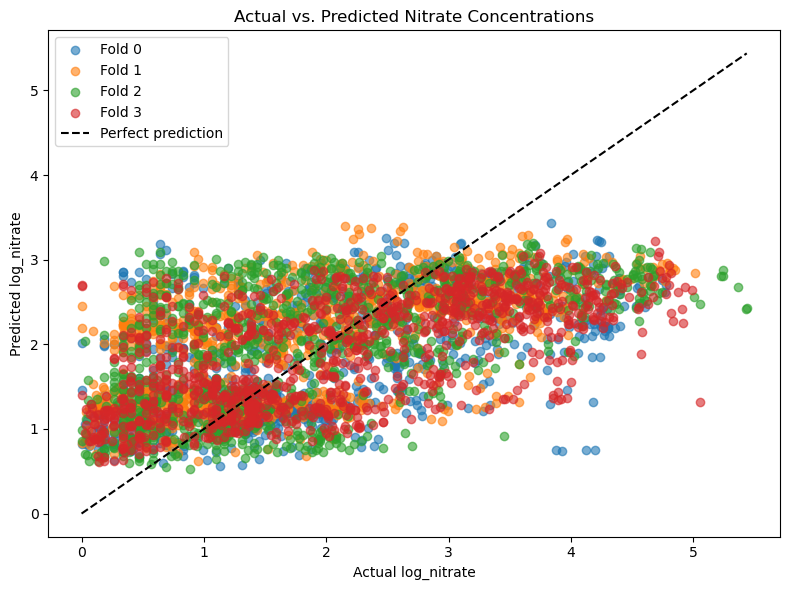

In [7]:
# 1. Actual vs. predicted
random_forest.plot_actual_vs_predicted(results, LOG_SCALE=True)


Actual nitrate concentrations against OOF predictions, with a separate color for each outer fold.

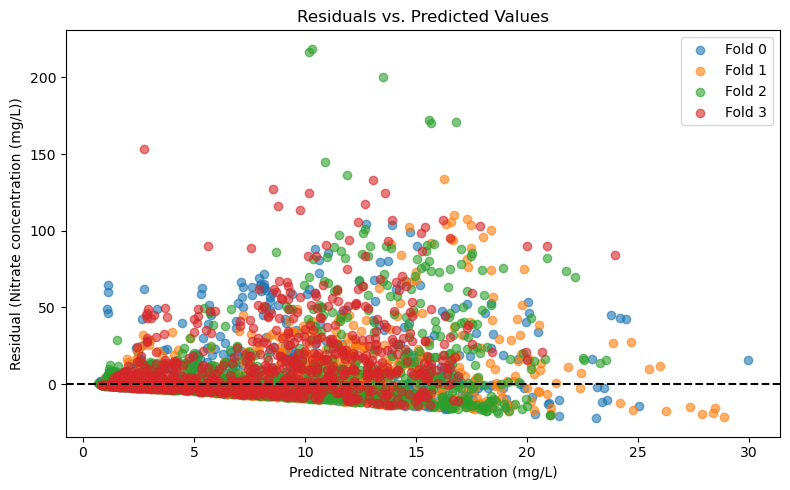

In [8]:
# 2. Residuals vs. predicted
random_forest.plot_residuals(results)

Positive residuals indicate underprediction; negative residuals indicate overprediction. The model severely underpredicts. 

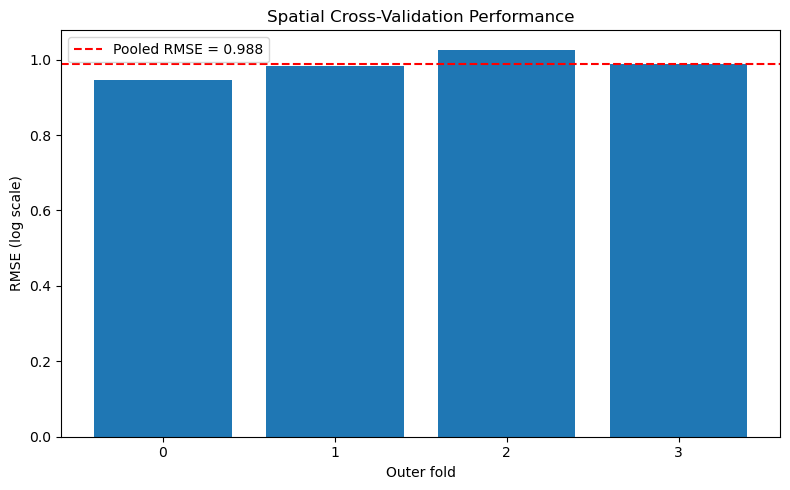

In [9]:
# 3. RMSE by outer fold
random_forest.plot_rmse_by_fold(results)

Just a visualization of RMSE per fold. 

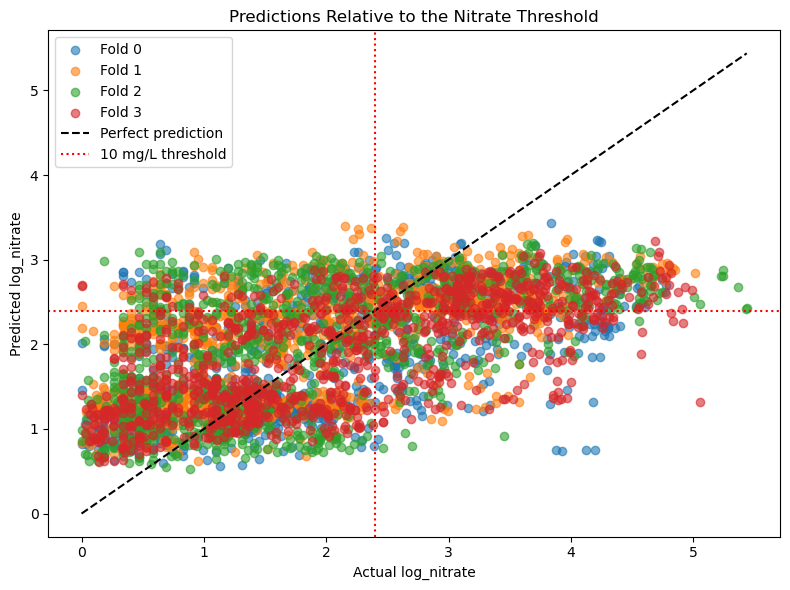

In [10]:
# 4. Predictions relative to the 10 mg/L threshold
random_forest.plot_threshold_results(results, LOG_SCALE=True)

| Actual | Predicted | Interpretation |
|---|---|---|
| Below 10 | Below 10 | Correctly identified as below threshold |
| Above 10 | Above 10 | Correctly identified as above threshold |
| Above 10 | Below 10 | False negative |
| Below 10 | Above 10 | False positive |

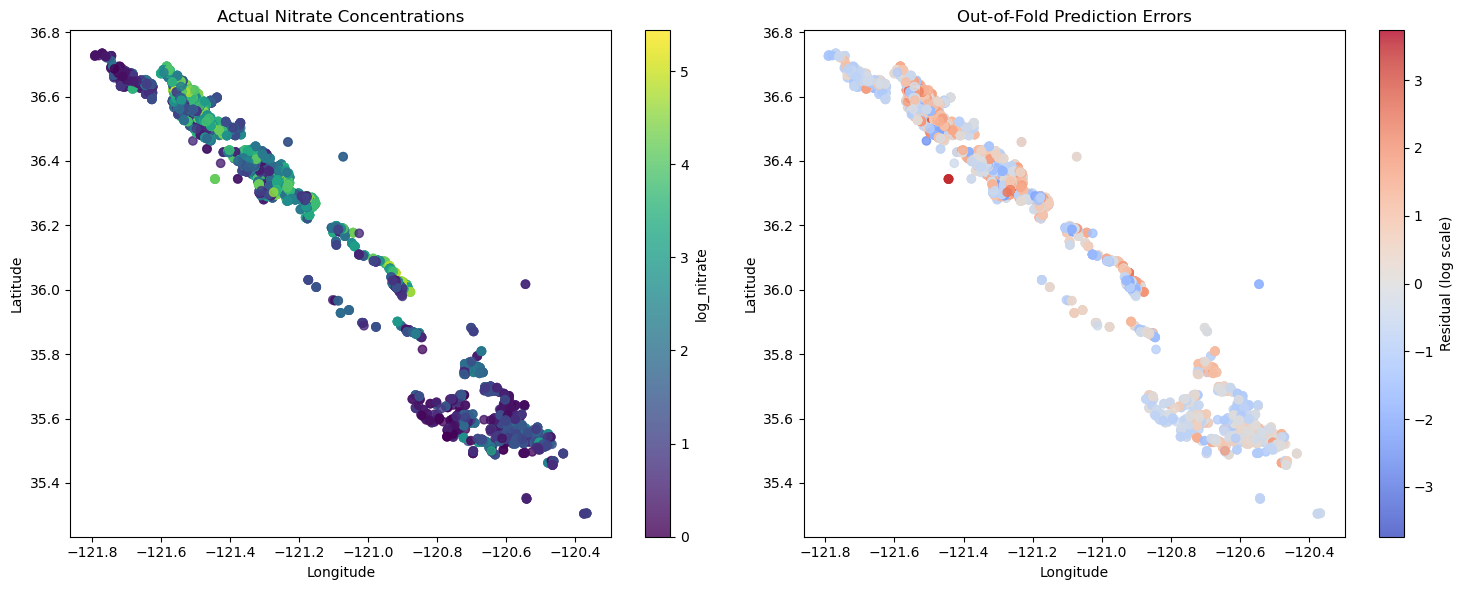

In [11]:
# 5. Spatial maps
random_forest.plot_spatial_results(results, development, LOG_SCALE=True)

1. Actual nitrate concentrations at the sampled locations.
2. OOF prediction errors at those locations.
Positive/negative residuals indicate underprediction/overprediction.

In [12]:
score_df = pd.DataFrame({'feature':X.columns,
                            'importance_score': model.feature_importances_})

score_df.sort_values('importance_score',ascending=False)

,feature,importance_score
7,pct_veg_berry_500m,0.082687
1,soil_slopegradwta,0.062855
15,pct_multicrop_500m,0.053301
42,historical_mean_temperature_c,0.053074
14,crop_cycles_500m,0.044597
39,historical_mean_annual_precip_mm,0.044358
21,outside_dwr_polygons_pct_1000m,0.040685
2,soil_aws0150wta,0.036914
8,pct_vineyard_500m,0.036788
49,subbasin_180/400 FOOT AQUIFER,0.034662


Elevation by far has the highest importance score. 

In [13]:
from src.evaluation.results_log import save_run, load_runs, summarize

save_run(results["outer_results"], model="RandomForestRegressor", task="regression", author="Charlsey",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(FEATURES))

#The scores table needs a "fold" column plus rmse_log and r2 (regression) or auc and brier_skill (classification).
#Each run is saved as its own small CSV in results/model_runs/ (one file per model and config, 
# so we don't get Git conflicts), so please commit those files too.

#To see everything combined (mean and SD across folds):
summarize(load_runs(), task="regression")
#summarize(load_runs(), task="classification")

Saved 4 folds to results\model_runs\charlsey__randomforestregressor__regression__5km-subbasin__subbasin1__noelev1.csv


rmse_log  \
                                                                                         mean   
task       model                 author   split          use_subbasin drop_elevation            
regression Lasso                 Andrea   10km_subbasin  True         True              1.016   
                                          5km_subbasin   True         True              1.031   
           RandomForestRegressor Charlsey 10km           False        False             1.072   
                                          10km_subbasin  True         True              0.972   
                                          5km_subbasin   True         True              0.986   
                                          7.5km_subbasin True         True              0.998   
           Ridge                 Andrea   10km_subbasin  True         True              1.031   
                                          5km_subbasin   True         True              1.033   

                                                                                             \
                                                                                        std   
task       model                 author   split          use_subbasin drop_elevation          
regression Lasso                 Andrea   10km_subbasin  True         True            0.081   
                                          5km_subbasin   True         True            0.012   
           RandomForestRegressor Charlsey 10km           False        False           0.044   
                                          10km_subbasin  True         True            0.062   
                                          5km_subbasin   True         True            0.033   
                                          7.5km_subbasin True         True            0.068   
           Ridge                 Andrea   10km_subbasin  True         True            0.068   
                                          5km_subbasin   True         True            0.010   

                                                                                         r2  \
                                                                                       mean   
task       model                 author   split          use_subbasin drop_elevation          
regression Lasso                 Andrea   10km_subbasin  True         True            0.284   
                                          5km_subbasin   True         True            0.264   
           RandomForestRegressor Charlsey 10km           False        False           0.235   
                                          10km_subbasin  True         True            0.345   
                                          5km_subbasin   True         True            0.327   
                                          7.5km_subbasin True         True            0.296   
           Ridge                 Andrea   10km_subbasin  True         True            0.263   
                                          5km_subbasin   True         True            0.261   

                                                                                             
                                                                                        std  
task       model                 author   split          use_subbasin drop_elevation         
regression Lasso                 Andrea   10km_subbasin  True         True            0.063  
                                          5km_subbasin   True         True            0.048  
           RandomForestRegressor Charlsey 10km           False        False           0.113  
                                          10km_subbasin  True         True            0.058  
                                          5km_subbasin   True         True            0.035  
                                          7.5km_subbasin True         True            0.089  
           Ridge                 Andrea   10km_subbasin  True         True     